# SBP 3D analysis — full disk and thread tilts

The figures use the same plotting functions as the corrected-geometry full-tilt report. Only imports, file locations and figure display are changed. The original 1D figure sequence is in [sbp_1d_analysis.ipynb](sbp_1d_analysis.ipynb).

The model is fitted to **corrected complex S22 on the four measured chords**, with 17 shared geometry parameters: 3 disk shifts, 6 disk slopes and 8 thread-endpoint shifts. One complex response scale per frequency and an affine complex background per chord are profiled analytically. No Gaussian/radial field is fed into this likelihood; preliminary Gaussian fits only select the 33 geometry-fit frequencies.

**Saved result:** corrected nominal mirror gap 7.803 mm, 20–22 GHz. Its uncertainty band is conditional on the geometry, beam and calibration assumptions. Several fitted shifts hit their bounds and weak-thread residuals remain large. This is not a validated geometry or a total boost uncertainty. All heavy numerical data stay outside Git; rendered figures are included below.

In [1]:
from pathlib import Path
import json
import numpy as np
from src import analysis_3d_plots as plots
from src import pipeline_plots as measurement_plots

measurement_plots.configure_style()
DATA = Path("data/3d")
RUN_DIR = Path("data/spider_bead_pull_runs/run_20261025_141003")
FREQUENCY_GHZ = 20.825
plots.FREQUENCIES = (20.795, FREQUENCY_GHZ)
SAVE_FIGURES = False
FIGURE_DIR = Path("outputs/sbp_3d/plots") if SAVE_FIGURES else None

result = plots.load(DATA / "disk_tilts_threads.npz")
bands = plots.load(DATA / "conditional_bands.npz")
maps = plots.load(DATA / "field_maps.npz")
geometry = json.loads(Path("config/full_tilt_geometry.json").read_text())

## 1. Conditional boost factor

One curve and a shaded 16–84% conditional interval; full band and resonance view.

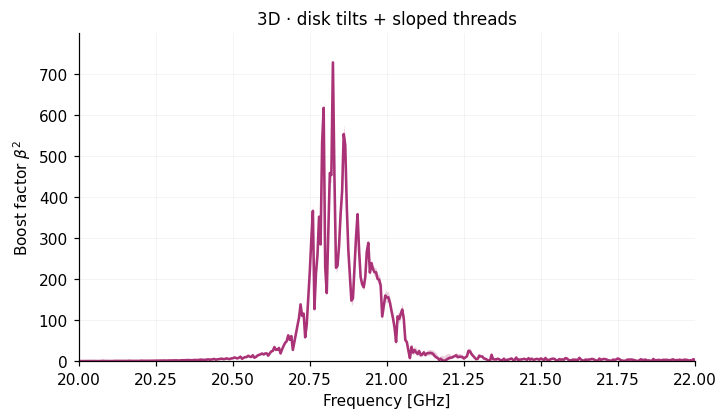

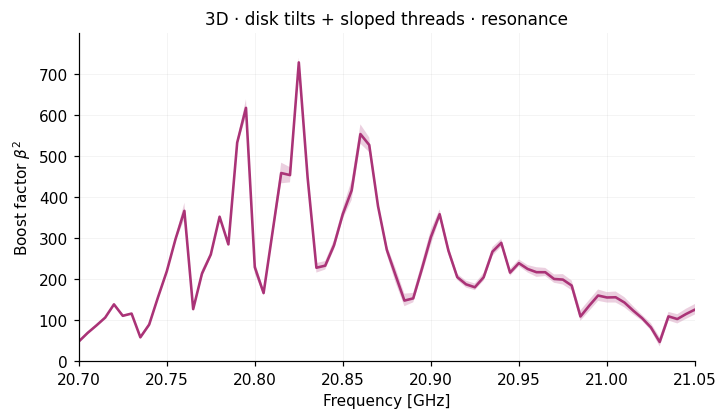

In [2]:
plots.present(plots.boost_figures(result, bands), FIGURE_DIR)

## 2. Raw measurement and incident beam

Raw reflection versus position, followed by the independently measured beam-width input. Reference scan z = 50–100 mm has no measured registration to the spider mirror; its six magnitude profiles are combined at the outer reference face, normalized to 1 W over the whole plane, with a flat phase assumption.

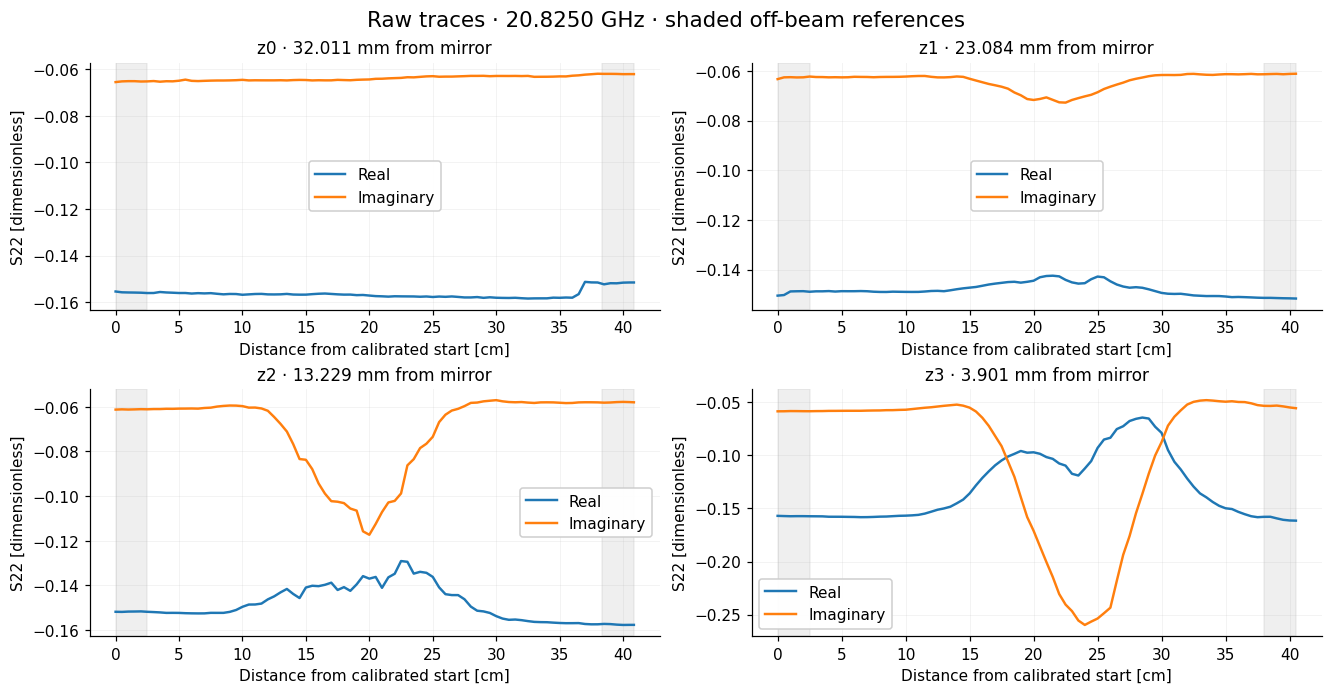

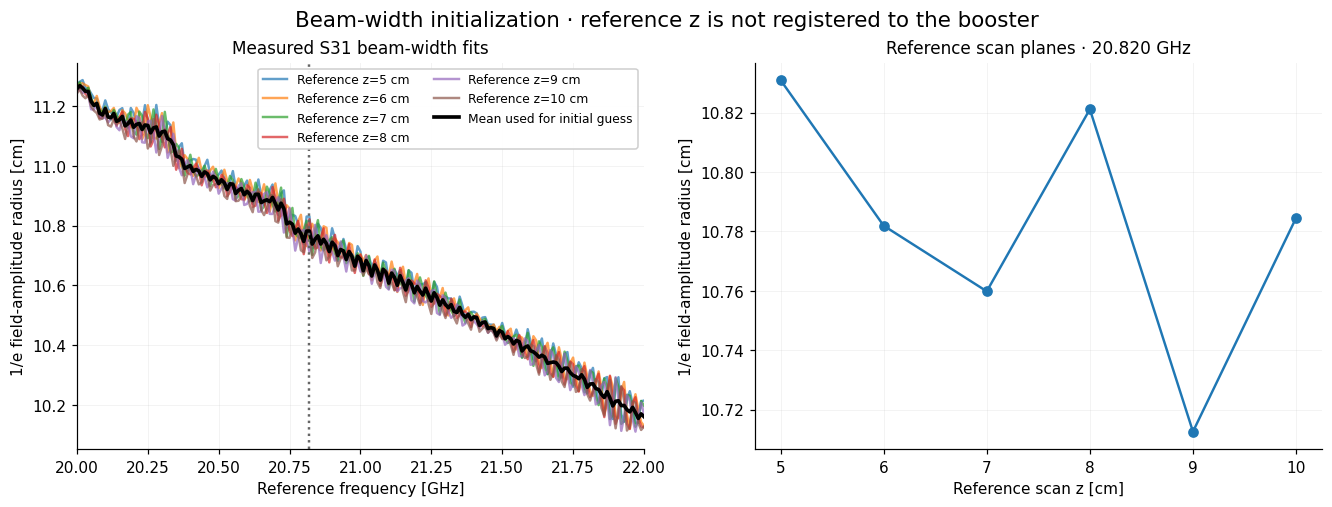

In [3]:
measurement = measurement_plots.load_pipeline(RUN_DIR, frequency_range_GHz=(20., 22.))
measurement_plots.present(
    measurement_plots.plot_raw_traces(measurement, FREQUENCY_GHZ), "raw_complex_traces", FIGURE_DIR,
)
measurement_plots.present(
    measurement_plots.plot_beam_reference(measurement, FREQUENCY_GHZ), "incident_beam_widths", FIGURE_DIR,
)

## 3. Complex measured and fitted chord profiles

The same fitted affine background is removed from both series. T0 is included, and each point uses its own fitted z.

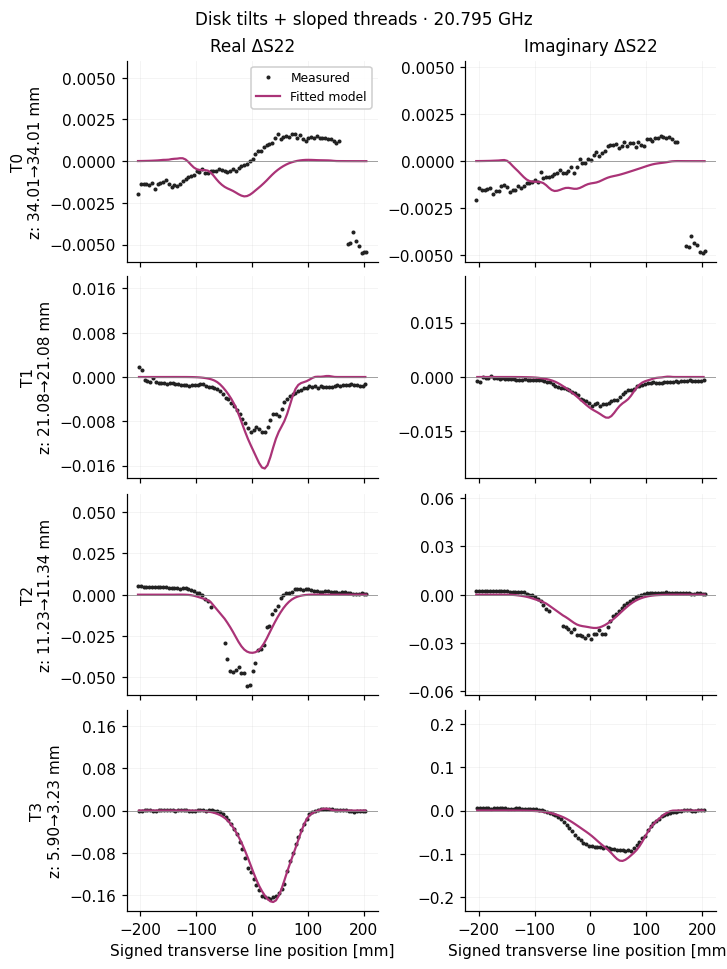

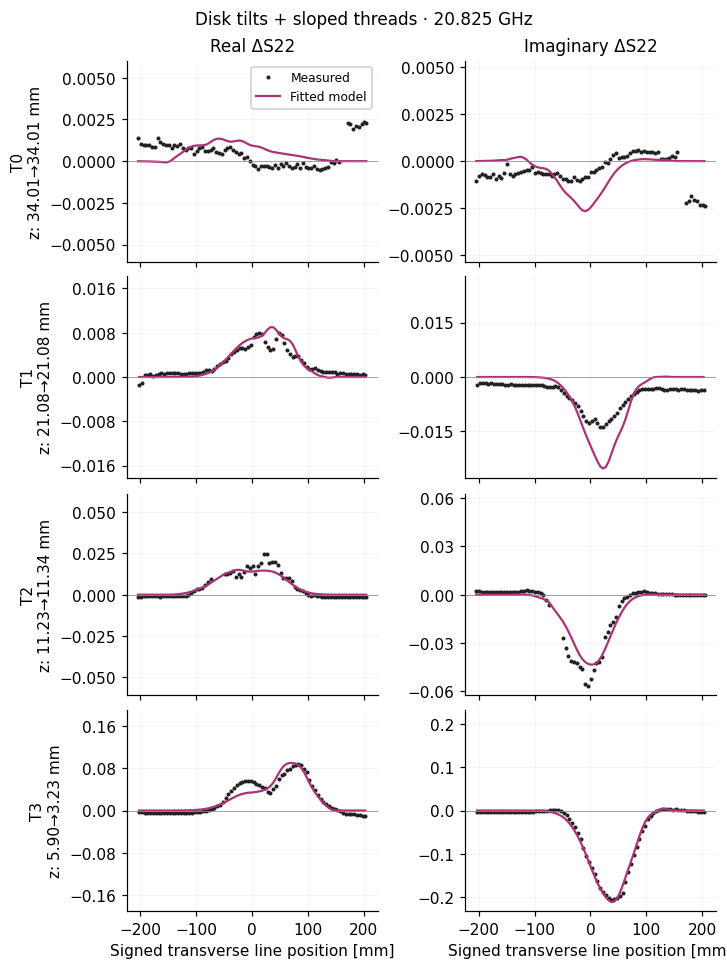

In [4]:
plots.present(plots.profile_figures(result), FIGURE_DIR)

## 4. Finite-bead magnitude along each chord

These line plots show the finite-bead response, in V/m; they are distinct from the model electric-field maps in the next section.

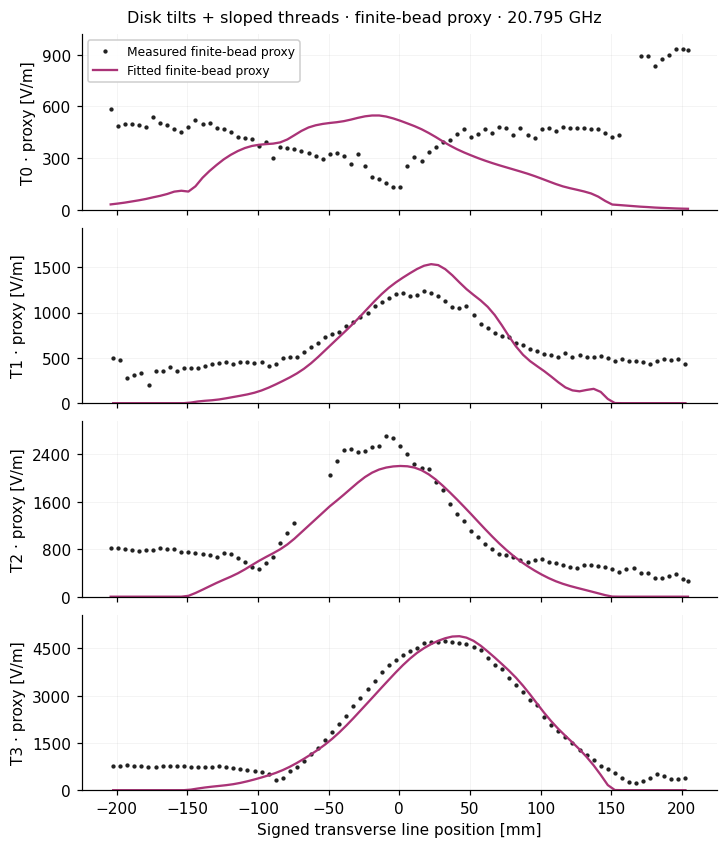

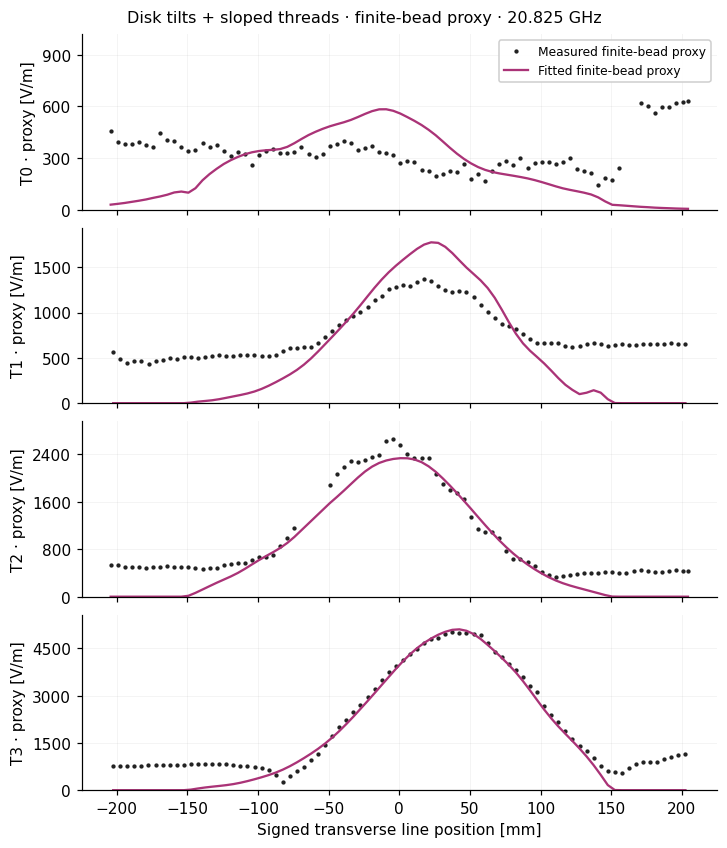

In [5]:
field_figures, _ = plots.effective_field_figures(result)
plots.present(field_figures, FIGURE_DIR)

## 5. Transverse electric-field maps

Model $|E|$ without the bead, including the fitted amplitude scale. Each horizontal section is at the corresponding thread midpoint. Blank pixels follow the aperture/clearance display mask; T0 extends outside the disk. The black/white dotted overlay marks one projected chord.

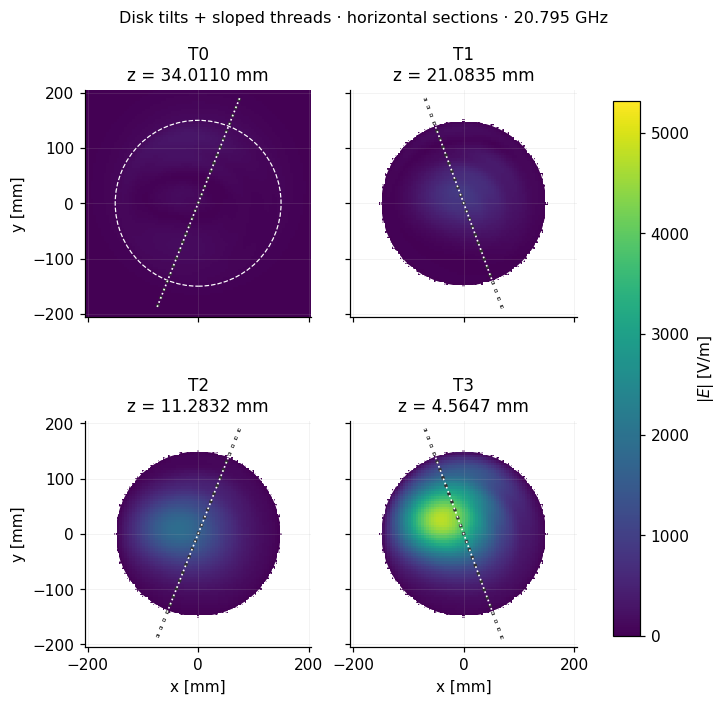

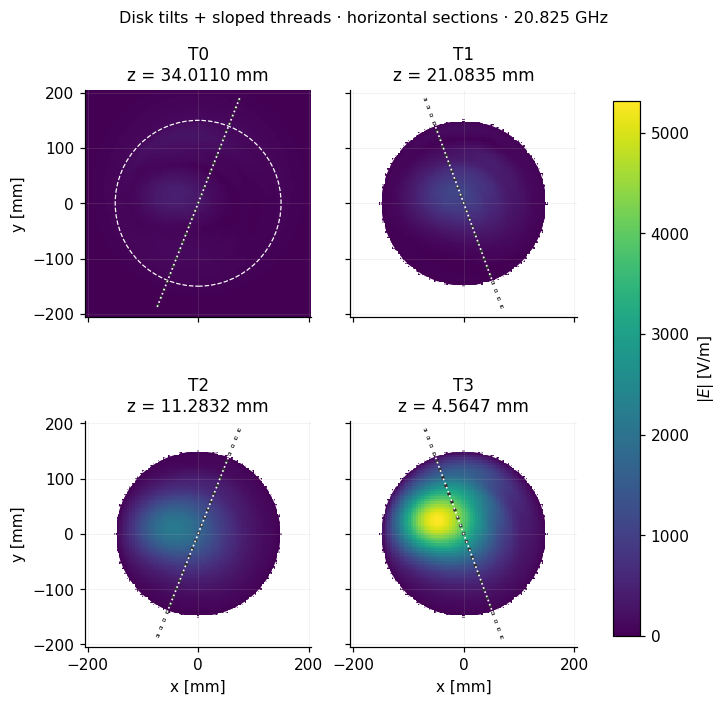

In [6]:
plots.present(plots.field_map_figures(maps, result, geometry), FIGURE_DIR)

## 6. Geometry

Nominal and fitted positions, endpoint shifts, disk slopes, and an oblique view. Projection and adjustment plots are separate, as in the report. Axial dimensions are enlarged for visibility; A/B are retained scan endpoints, not mechanical supports.

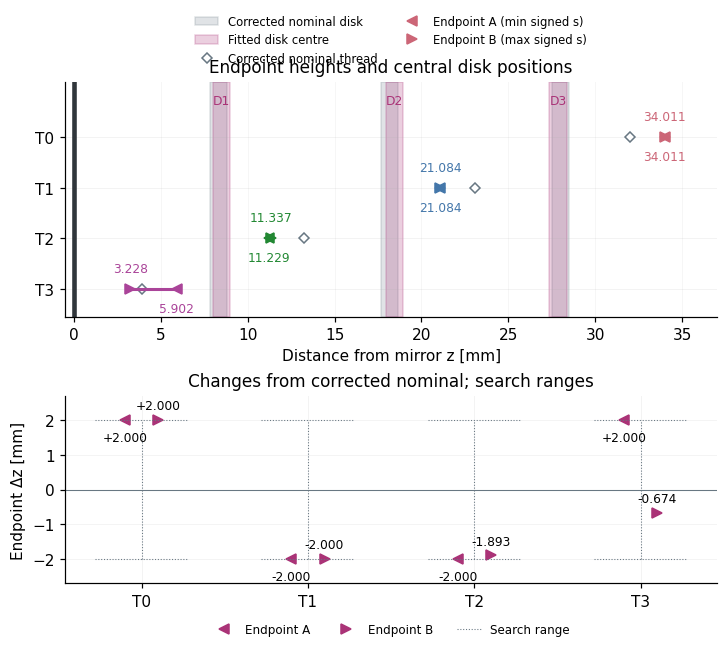

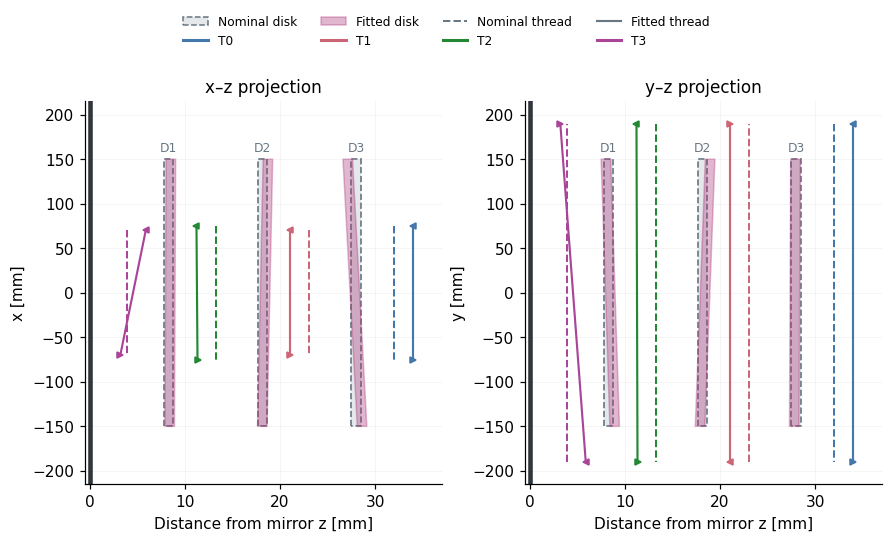

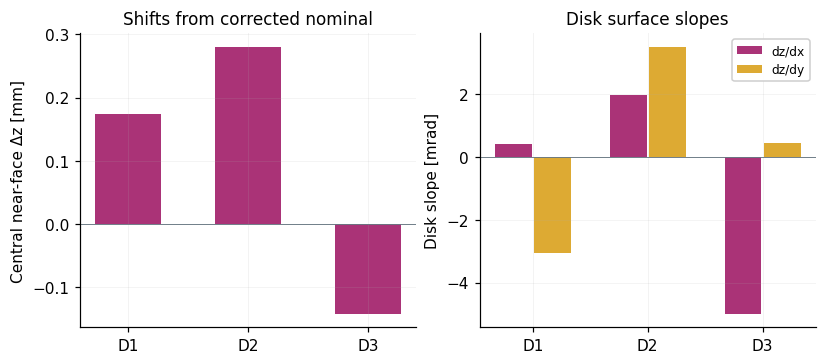

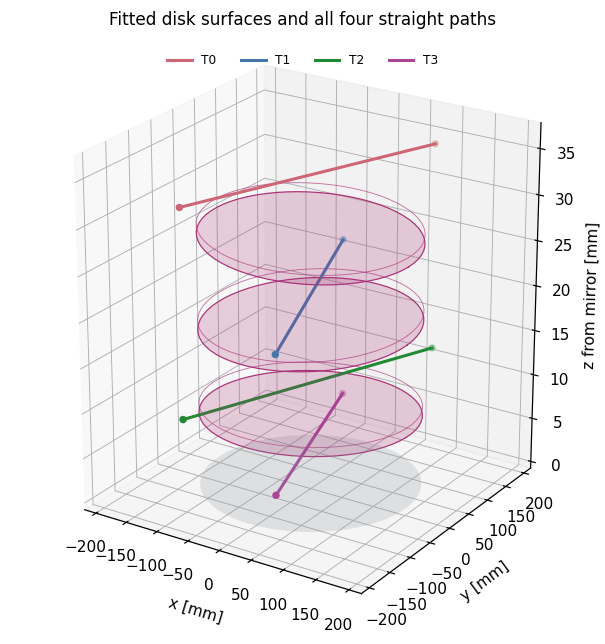

In [7]:
plots.present(plots.geometry_figures(geometry), FIGURE_DIR)

## 7. Residuals

Combined and individual-thread residuals use the same fitted common scale. The selected 33 bins determine geometry; the rest of the band is a diagnostic.

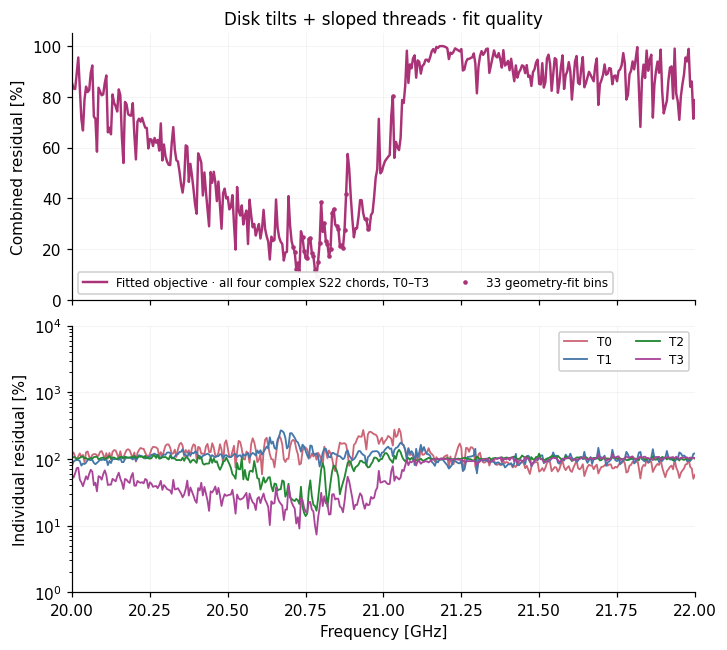

In [8]:
plots.present(plots.residual_figure(result), FIGURE_DIR)

## 8. Full bead-pull comparison

The saved full-scan reference spans 20.5–21.5 GHz. Curves retain their saved normalizations; their absolute calibration has not been reconciled.

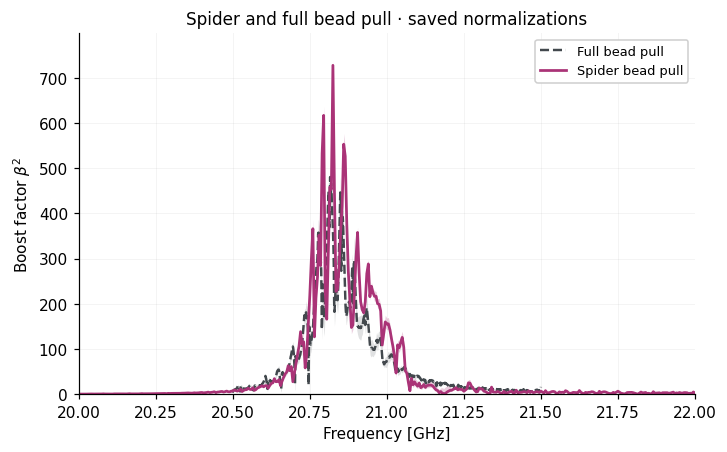

In [9]:
from src.full_bead_comparison import load_full_bead
full = load_full_bead("data/full_bead_pull/result_bf_21_0.jld2")
reference = {"frequency_hz": full.frequencies_Hz, "beta2_saved": full.beta2, "beta2_saved_error": full.beta2_error}
plots.present(plots.reference_figure(result, bands, reference, "Saved normalizations differ."), FIGURE_DIR)

### Coherent transverse field integral

Both series below are model-derived fields in their saved normalizations. Spider points are integrals over horizontal midpoint sections, not a radial rotation of the sloped chord measurement.

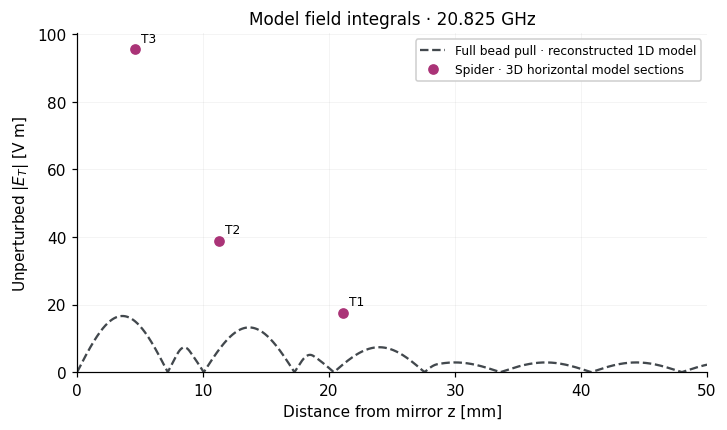

In [10]:
from src.full_bead_model import evaluate_full_model

z = np.linspace(0, .05, 1001)
k = np.argmin(abs(full.frequencies_Hz - FREQUENCY_GHZ * 1e9))
full_field = evaluate_full_model(full.frequencies_Hz[k], z, full.parameters_at(k))
field_reference = {"frequency_hz": np.array([full.frequencies_Hz[k]]), "z_m": z,
                   "field_Vm": full_field.field.T}
plots.present(plots.reference_field_figure(maps, field_reference), FIGURE_DIR)

## 9. Recompute from measurements (optional)

These switches are off so that opening the notebook only renders saved results. Preprocessing reproduces the original rank-one drift correction and frequency mask; it does not construct the model illumination from the spider data.

In [11]:
from src.analysis_3d_inputs import prepare_measurement, prepare_beam

REPROCESS = False
if REPROCESS:
    prepare_measurement(RUN_DIR, DATA / "measurement_inputs.npz")
    prepare_beam("data/reference_data/beam_measurements/beam_fit_S31.csv",
                 DATA / "beam_prior.npz", result["frequency_hz"])

## 10. Fit or evaluate the 3D model (optional)

The default 120-mode propagation bank contains the 33 selected geometry-fit frequencies. Use a bank with all 401 frequencies for a full-band export. A new fit below is a single explicit SLSQP start; the saved original result came from multiple starts. Julia/CUDA is used to build the bank; the small modal solves and optimization run in Python.

In [12]:
from src.analysis_3d import EndpointFitProblem, fit_full_tilt, save_result

EVALUATE_MODEL = False
RUN_FIT = False
if EVALUATE_MODEL or RUN_FIT:
    problem = EndpointFitProblem(DATA / "bank", DATA / "measurement_inputs.npz", DATA / "beam_prior.npz")
    parameters = np.asarray(geometry["parameters"])
    details = {"operation": "evaluation of saved geometry"}
    if RUN_FIT:
        # Start from measured central positions and measured relative disk slopes.
        initial = np.zeros(17)
        initial[3:9] = np.asarray(geometry["nominal_disk_slopes_mrad"]).ravel()
        optimization = fit_full_tilt(problem, initial, maxiter=180)
        parameters = optimization.x
        details = {"success": bool(optimization.success), "message": str(optimization.message),
                   "iterations": int(optimization.nit), "starts": 1}
    record, evaluated = save_result(problem, parameters, "outputs/sbp_3d", details)

## 11. Export conditional bands and midpoint maps (optional)

The bootstrap keeps geometry and illumination fixed. The default bank does not contain 21 GHz, so this example exports only the two displayed map frequencies.

In [13]:
from src.analysis_3d_exports import conditional_bands, midpoint_maps

EXPORT = False
if EXPORT:
    quantiles = conditional_bands(evaluated, problem.fit_threads, draws=1000)
    np.savez_compressed("outputs/sbp_3d/conditional_bands.npz", frequency_hz=evaluated["frequency_hz"],
                       quantiles=quantiles, quantile_probabilities=[.025, .16, .5, .84, .975])
    midpoint_maps(problem, parameters, "outputs/sbp_3d", frequencies_hz=[20.795e9,20.825e9])